<a href="https://colab.research.google.com/github/SrijaDas06/pharmacy-market-basket-analysis/blob/main/MarketBasketAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Market Basket Analysis for Pharmacy Inventory Management
**Apriori vs FP-Growth on co-prescription patterns, grouped by symptom**

Pipeline: upload data → parse transactions → one-hot encode → Apriori + FP-Growth → association rules (support, confidence, lift) → symptom-wise tables → comparison → figures → Excel export.

In [1]:
!pip install -q mlxtend openpyxl

import ast, time, re, io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

In [2]:
import os
try:
    from google.colab import files
    uploaded = files.upload()          # pick all the .xlsx files
    print("Uploaded:", list(uploaded.keys()))
except ImportError:
    print("Not running in Colab. Place the .xlsx files in the working directory.")

xlsx_files = [f for f in os.listdir(".") if f.lower().endswith(".xlsx")]

def find_file(keyword):
    for f in xlsx_files:
        if keyword.lower() in f.lower():
            return f
    return None

SYMPTOM_FILES = {
    "Fever, Cough, Headache & Body Pain": find_file("fever"),
    "Pressure":                           find_file("pressure"),
    "Hypertension":                       find_file("hypertension"),
    "Gastric, Vomiting, Food Poisoning":  find_file("gastric"),
}
ALL_DATA_FILE = find_file("all_data")

for k, v in SYMPTOM_FILES.items():
    print(f"{k:40s} -> {v}")
print("All-data file (optional):", ALL_DATA_FILE)
assert all(SYMPTOM_FILES.values()), "A symptom file is missing. Re-run the upload cell."

Saving all data with each med frequency (2).xlsx to all data with each med frequency (2).xlsx
Saving fever,cough,headache,bodypain Apriori & Fp final.xlsx to fever,cough,headache,bodypain Apriori & Fp final.xlsx
Saving hypertension Apriori & FP final.xlsx to hypertension Apriori & FP final.xlsx
Saving pressure Apriori & FP final.xlsx to pressure Apriori & FP final.xlsx
Saving Gastric, vomiting, food Apriori &FP final.xlsx to Gastric, vomiting, food Apriori &FP final.xlsx
Uploaded: ['all data with each med frequency (2).xlsx', 'fever,cough,headache,bodypain Apriori & Fp final.xlsx', 'hypertension Apriori & FP final.xlsx', 'pressure Apriori & FP final.xlsx', 'Gastric, vomiting, food Apriori &FP final.xlsx']
Fever, Cough, Headache & Body Pain       -> fever,cough,headache,bodypain Apriori & Fp final.xlsx
Pressure                                 -> pressure Apriori & FP final.xlsx
Hypertension                             -> hypertension Apriori & FP final.xlsx
Gastric, Vomiting, Food Poiso

In [3]:
MIN_SUPPORT    = 0.30   # minimum support for frequent itemsets
MIN_CONFIDENCE = 0.50   # minimum confidence for rules
DECIMALS       = 2      # rounding used in the paper tables

In [4]:
def parse_transaction(cell):
    """Handles both formats found in the workbooks:
       "['LASIX', 'RANTAC']"  (python-list string)  and  "LASIX, RANTAC"  (comma separated)."""
    s = str(cell).strip()
    if s.startswith("["):
        items = ast.literal_eval(s)
    else:
        items = s.split(",")
    items = [re.sub(r"\s+", " ", i).strip().upper() for i in items]
    # de-duplicate within a transaction, keep order
    return list(dict.fromkeys(i for i in items if i))

def load_transactions(path, sheet="dummy data"):
    df = pd.read_excel(path, sheet_name=sheet)
    col = df.columns[1]                       # 2nd column holds the medicines
    return df[col].dropna().apply(parse_transaction).tolist()

def one_hot(transactions):
    te = TransactionEncoder()
    arr = te.fit(transactions).transform(transactions)
    return pd.DataFrame(arr, columns=te.columns_)

DATA = {}
for symptom, path in SYMPTOM_FILES.items():
    tx = load_transactions(path)
    DATA[symptom] = {"transactions": tx, "onehot": one_hot(tx)}
    sizes = [len(t) for t in tx]
    print(f"{symptom:40s} transactions={len(tx):3d}  unique medicines={DATA[symptom]['onehot'].shape[1]:3d}  "
          f"avg basket={np.mean(sizes):.1f}")

Fever, Cough, Headache & Body Pain       transactions= 32  unique medicines= 19  avg basket=2.8
Pressure                                 transactions= 20  unique medicines= 33  avg basket=8.8
Hypertension                             transactions= 20  unique medicines= 32  avg basket=6.5
Gastric, Vomiting, Food Poisoning        transactions= 30  unique medicines= 39  avg basket=6.6


In [5]:
def fmt(fs):
    return ", ".join(sorted(fs))

def run_mba(onehot, algo, min_support=MIN_SUPPORT, min_conf=MIN_CONFIDENCE):
    func = apriori if algo == "apriori" else fpgrowth
    t0 = time.perf_counter()
    itemsets = func(onehot, min_support=min_support, use_colnames=True)
    rules = association_rules(itemsets, metric="confidence", min_threshold=min_conf)
    elapsed = time.perf_counter() - t0

    rules["n_items"]     = rules["antecedents"].apply(len) + rules["consequents"].apply(len)
    rules["Antecedents"] = rules["antecedents"].apply(fmt)
    rules["Consequents"] = rules["consequents"].apply(fmt)
    rules = (rules[["Antecedents", "Consequents", "n_items", "support", "confidence", "lift"]]
             .sort_values(["support", "confidence", "lift"], ascending=False)
             .reset_index(drop=True))
    return itemsets, rules, elapsed

RESULTS = {}
for symptom, d in DATA.items():
    RESULTS[symptom] = {}
    for algo in ("apriori", "fpgrowth"):
        itemsets, rules, secs = run_mba(d["onehot"], algo)
        RESULTS[symptom][algo] = {"itemsets": itemsets, "rules": rules, "time": secs}
    print(f"{symptom:40s} frequent itemsets: "
          f"Apriori={len(RESULTS[symptom]['apriori']['itemsets'])}, "
          f"FP-Growth={len(RESULTS[symptom]['fpgrowth']['itemsets'])}  | "
          f"rules: Apriori={len(RESULTS[symptom]['apriori']['rules'])}, "
          f"FP-Growth={len(RESULTS[symptom]['fpgrowth']['rules'])}")

Fever, Cough, Headache & Body Pain       frequent itemsets: Apriori=6, FP-Growth=6  | rules: Apriori=4, FP-Growth=4
Pressure                                 frequent itemsets: Apriori=49, FP-Growth=49  | rules: Apriori=112, FP-Growth=112
Hypertension                             frequent itemsets: Apriori=13, FP-Growth=13  | rules: Apriori=10, FP-Growth=10
Gastric, Vomiting, Food Poisoning        frequent itemsets: Apriori=15, FP-Growth=15  | rules: Apriori=16, FP-Growth=16


In [6]:
def side_by_side(symptom, n_items):
    """Apriori and FP-Growth rules for rules with n_items medicines, joined on the rule."""
    a = RESULTS[symptom]["apriori"]["rules"]; a = a[a.n_items == n_items].drop(columns="n_items")
    f = RESULTS[symptom]["fpgrowth"]["rules"]; f = f[f.n_items == n_items].drop(columns="n_items")
    m = a.merge(f, on=["Antecedents", "Consequents"], how="outer", suffixes=(" (Apriori)", " (FP-Growth)"))
    m = m.sort_values(["support (Apriori)", "confidence (Apriori)"], ascending=False, na_position="last")
    return m.round(DECIMALS).reset_index(drop=True)

TABLES = {}
table_no = {  # (symptom, n_items) -> paper table label
    ("Fever, Cough, Headache & Body Pain", 2): "Table 3",
    ("Pressure", 2): "Table 4",
    ("Pressure", 3): "Table 5",
    ("Hypertension", 2): "Table 6",
    ("Gastric, Vomiting, Food Poisoning", 2): "Table 7",
    ("Gastric, Vomiting, Food Poisoning", 3): "Table 8",
}
for symptom in SYMPTOM_FILES:
    for n in (2, 3):
        t = side_by_side(symptom, n)
        if len(t):
            TABLES[(symptom, n)] = t
            print(f"\n{table_no.get((symptom, n), '')}  {n}-itemset rules | {symptom}")
            display(t)


Table 3  2-itemset rules | Fever, Cough, Headache & Body Pain


,Antecedents,Consequents,support (Apriori),confidence (Apriori),lift (Apriori),support (FP-Growth),confidence (FP-Growth),lift (FP-Growth)
0,SYRUP GRANOCYF,NASOCLEAR NASAL DROPS,0.34,1.00,2.46,0.34,1.00,2.46
1,NASOCLEAR NASAL DROPS,SYRUP GRANOCYF,0.34,0.85,2.46,0.34,0.85,2.46
2,PARACETAMOL (ACETAMINOPHEN),TRAMADOL,0.31,1.00,3.20,0.31,1.00,3.20
3,TRAMADOL,PARACETAMOL (ACETAMINOPHEN),0.31,1.00,3.20,0.31,1.00,3.20



Table 4  2-itemset rules | Pressure


,Antecedents,Consequents,support (Apriori),confidence (Apriori),lift (Apriori),support (FP-Growth),confidence (FP-Growth),lift (FP-Growth)
0,RANTAC 150,LASIX 40,0.60,0.86,1.14,0.60,0.86,1.14
1,LASIX 40,RANTAC 150,0.60,0.80,1.14,0.60,0.80,1.14
2,PAN 40,RANTAC 150,0.55,0.85,1.21,0.55,0.85,1.21
3,RANTAC 150,PAN 40,0.55,0.79,1.21,0.55,0.79,1.21
4,COLDVAN,LASIX 40,0.50,0.91,1.21,0.50,0.91,1.21
5,PAN 40,LASIX 40,0.50,0.77,1.03,0.50,0.77,1.03
6,AMLODIPINE 5,LASIX 40,0.50,0.71,0.95,0.50,0.71,0.95
7,LASIX 40,AMLODIPINE 5,0.50,0.67,0.95,0.50,0.67,0.95
8,LASIX 40,COLDVAN,0.50,0.67,1.21,0.50,0.67,1.21
9,LASIX 40,PAN 40,0.50,0.67,1.03,0.50,0.67,1.03



Table 5  3-itemset rules | Pressure


,Antecedents,Consequents,support (Apriori),confidence (Apriori),lift (Apriori),support (FP-Growth),confidence (FP-Growth),lift (FP-Growth)
0,"LASIX 40, PAN 40",RANTAC 150,0.45,0.90,1.29,0.45,0.90,1.29
1,"PAN 40, RANTAC 150",LASIX 40,0.45,0.82,1.09,0.45,0.82,1.09
2,"LASIX 40, RANTAC 150",PAN 40,0.45,0.75,1.15,0.45,0.75,1.15
3,PAN 40,"LASIX 40, RANTAC 150",0.45,0.69,1.15,0.45,0.69,1.15
4,RANTAC 150,"LASIX 40, PAN 40",0.45,0.64,1.29,0.45,0.64,1.29
...,...,...,...,...,...,...,...,...
58,CLOPITAB A 75,"AMLODIPINE 5, PAN 40",0.30,0.55,1.21,0.30,0.55,1.21
59,CLOPITAB A 75,"KIDZYME, PAN 40",0.30,0.55,1.36,0.30,0.55,1.36
60,COLDVAN,"AMLODIPINE 5, LASIX 40",0.30,0.55,1.09,0.30,0.55,1.09
61,COLDVAN,"LASIX 40, PAN 40",0.30,0.55,1.09,0.30,0.55,1.09


... (2 outputs left out)


Table 7  2-itemset rules | Gastric, Vomiting, Food Poisoning


,Antecedents,Consequents,support (Apriori),confidence (Apriori),lift (Apriori),support (FP-Growth),confidence (FP-Growth),lift (FP-Growth)
0,LASIX,AMLODIPINE,0.53,1.00,1.50,0.53,1.00,1.50
1,AMLODIPINE,LASIX,0.53,0.80,1.50,0.53,0.80,1.50
2,AMLODIPINE,RANTAC,0.53,0.80,1.14,0.53,0.80,1.14
3,RANTAC,AMLODIPINE,0.53,0.76,1.14,0.53,0.76,1.14
4,LASIX,RANTAC,0.40,0.75,1.07,0.40,0.75,1.07
5,RANTAC,LASIX,0.40,0.57,1.07,0.40,0.57,1.07
6,OMEPRAZOLE,RANTAC,0.37,0.85,1.21,0.37,0.85,1.21
7,RANTAC,OMEPRAZOLE,0.37,0.52,1.21,0.37,0.52,1.21
8,CLOPITAB A,AMLODIPINE,0.30,1.00,1.50,0.30,1.00,1.50
9,PAN,AMLODIPINE,0.30,0.69,1.04,0.30,0.69,1.04



Table 8  3-itemset rules | Gastric, Vomiting, Food Poisoning


,Antecedents,Consequents,support (Apriori),confidence (Apriori),lift (Apriori),support (FP-Growth),confidence (FP-Growth),lift (FP-Growth)
0,"LASIX, RANTAC",AMLODIPINE,0.4,1.00,1.50,0.4,1.00,1.50
1,"AMLODIPINE, LASIX",RANTAC,0.4,0.75,1.07,0.4,0.75,1.07
2,"AMLODIPINE, RANTAC",LASIX,0.4,0.75,1.41,0.4,0.75,1.41
3,LASIX,"AMLODIPINE, RANTAC",0.4,0.75,1.41,0.4,0.75,1.41
4,AMLODIPINE,"LASIX, RANTAC",0.4,0.60,1.50,0.4,0.60,1.50
5,RANTAC,"AMLODIPINE, LASIX",0.4,0.57,1.07,0.4,0.57,1.07


In [7]:
def rules_signature(rules):
    return set(zip(rules.Antecedents, rules.Consequents, rules.support.round(6),
                   rules.confidence.round(6), rules.lift.round(6)))

def avg_time(onehot, algo, repeats=30):
    ts = [run_mba(onehot, algo)[2] for _ in range(repeats)]
    return float(np.mean(ts)) * 1000   # ms

rows = []
for symptom, d in DATA.items():
    ra, rf = RESULTS[symptom]["apriori"]["rules"], RESULTS[symptom]["fpgrowth"]["rules"]
    rows.append({
        "Symptom": symptom,
        "Transactions": len(d["transactions"]),
        "Unique medicines": d["onehot"].shape[1],
        "Rules (Apriori)": len(ra),
        "Rules (FP-Growth)": len(rf),
        "Identical rule sets": rules_signature(ra) == rules_signature(rf),
        "Avg time Apriori (ms)": round(avg_time(d["onehot"], "apriori"), 2),
        "Avg time FP-Growth (ms)": round(avg_time(d["onehot"], "fpgrowth"), 2),
    })
COMPARISON = pd.DataFrame(rows)
display(COMPARISON)

,Symptom,Transactions,Unique medicines,Rules (Apriori),Rules (FP-Growth),Identical rule sets,Avg time Apriori (ms),Avg time FP-Growth (ms)
0,"Fever, Cough, Headache & Body Pain",32,19,4,4,True,5.79,5.65
1,Pressure,20,33,112,112,True,7.59,10.04
2,Hypertension,20,32,10,10,True,5.79,6.63
3,"Gastric, Vomiting, Food Poisoning",30,39,16,16,True,6.04,6.63


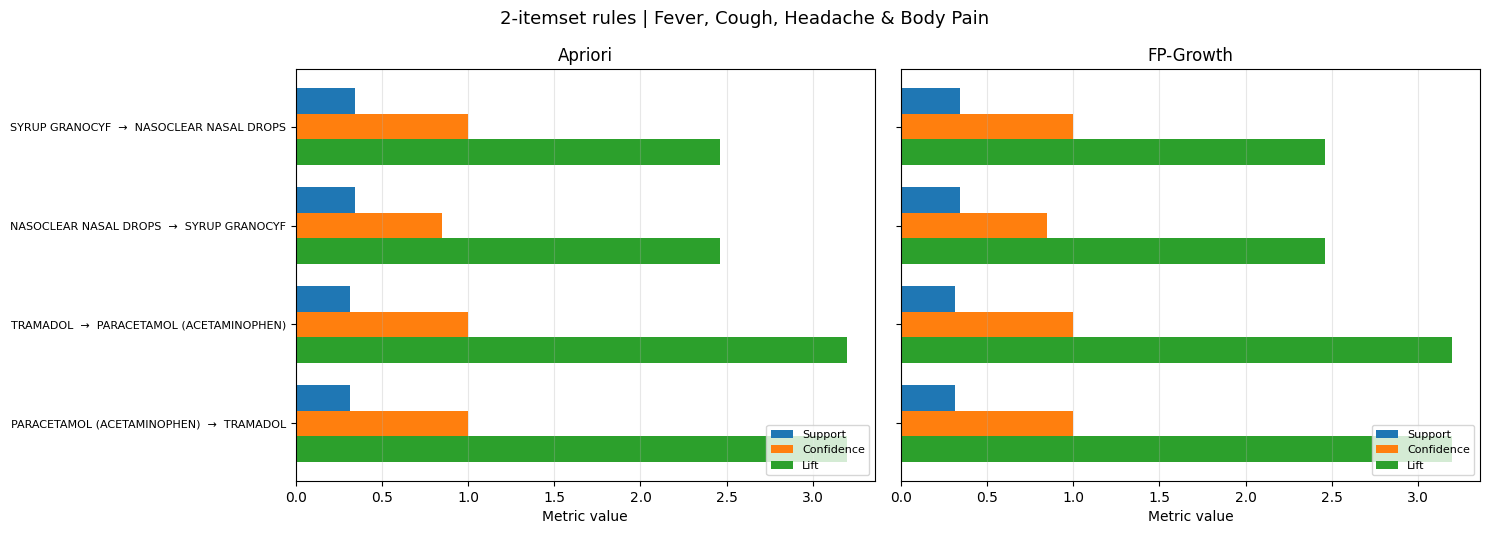

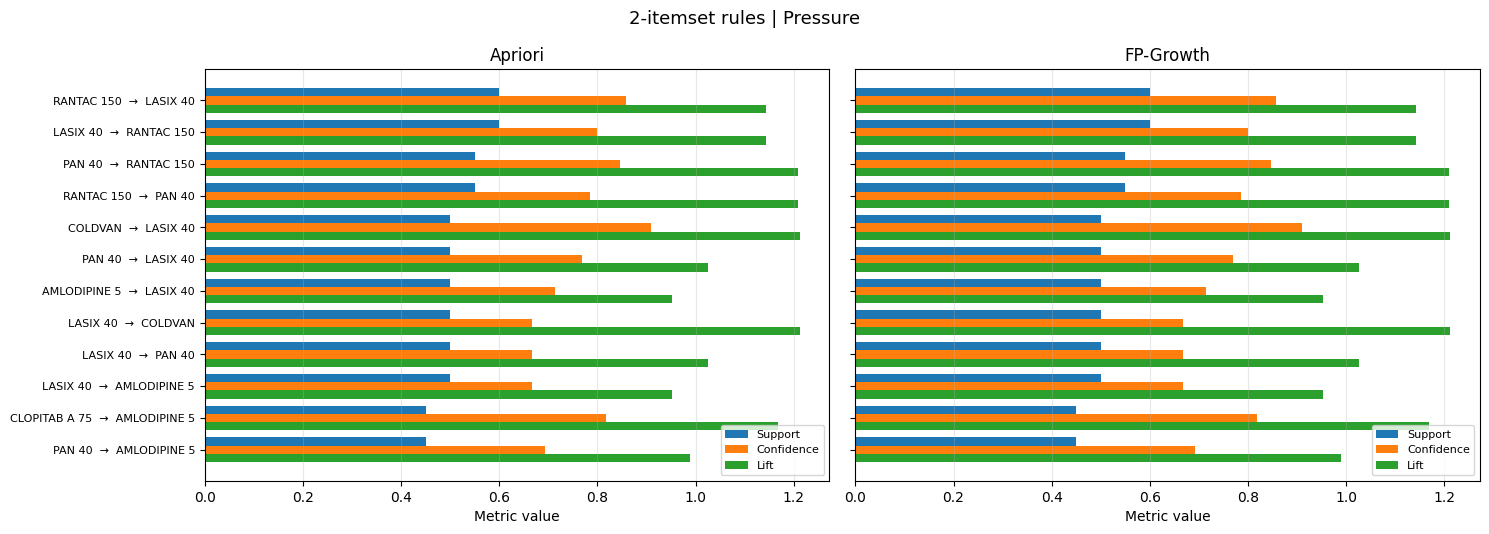

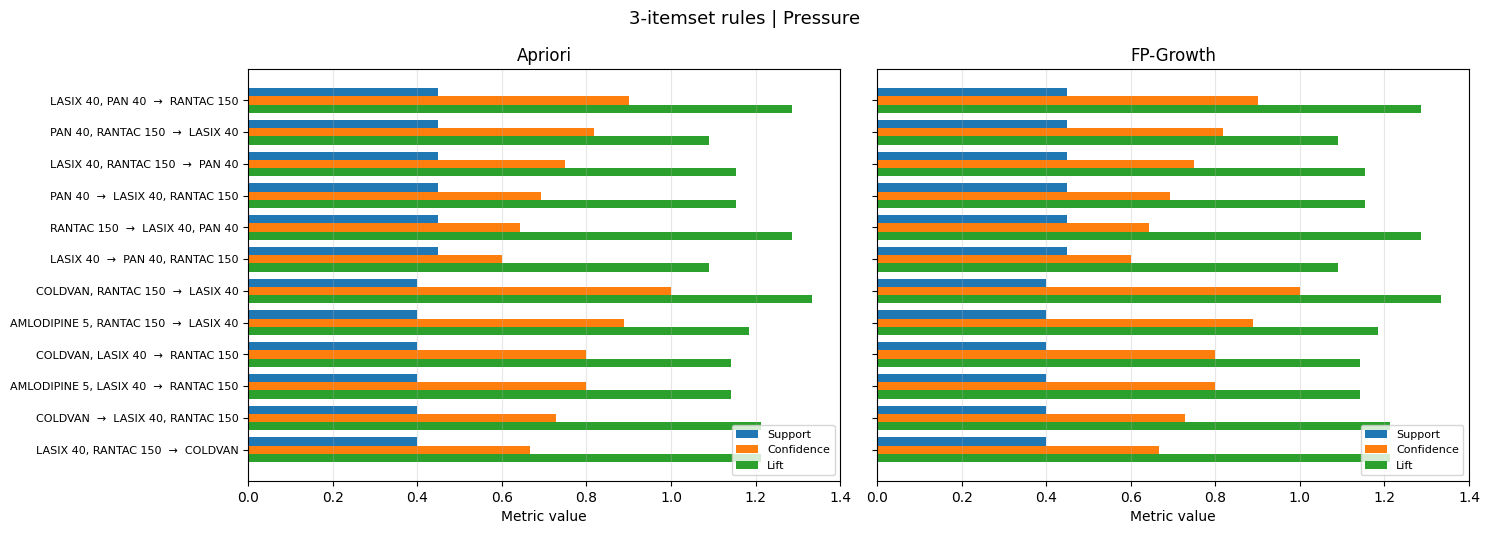

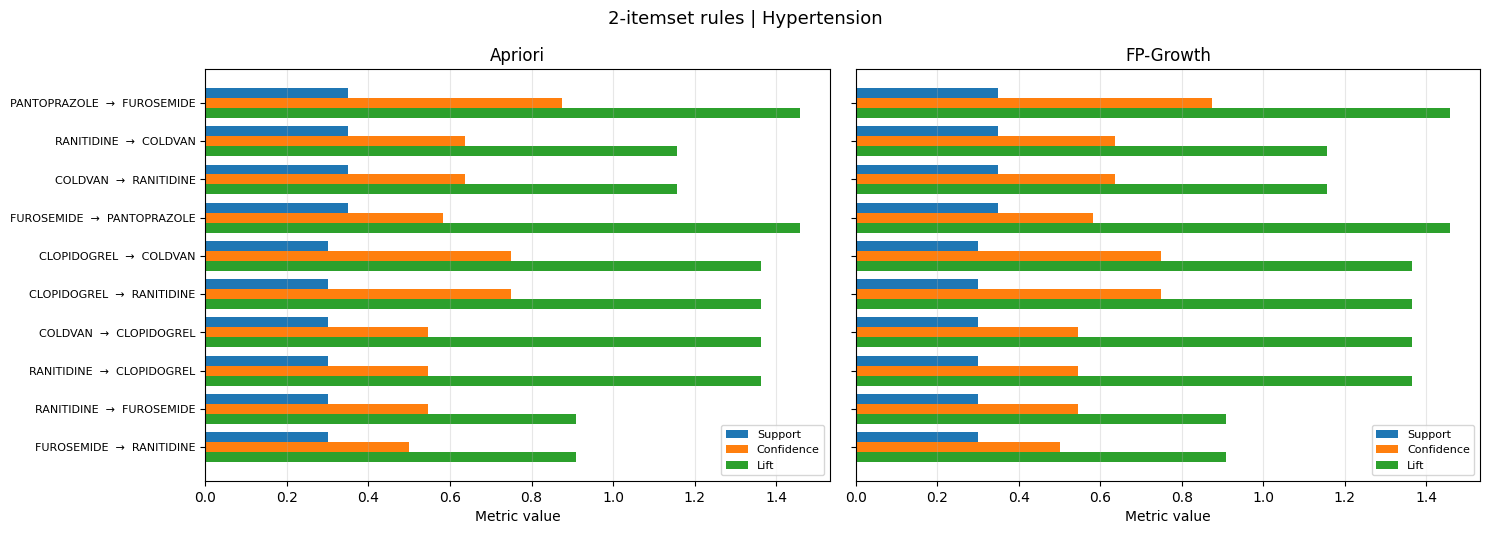

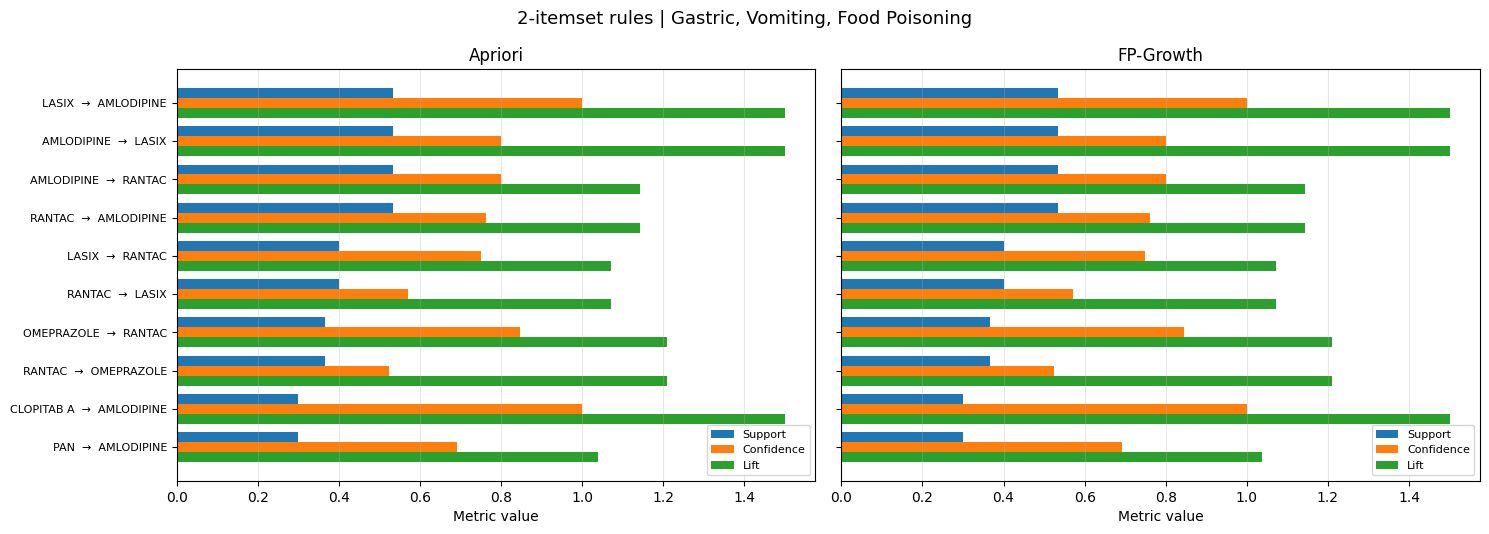

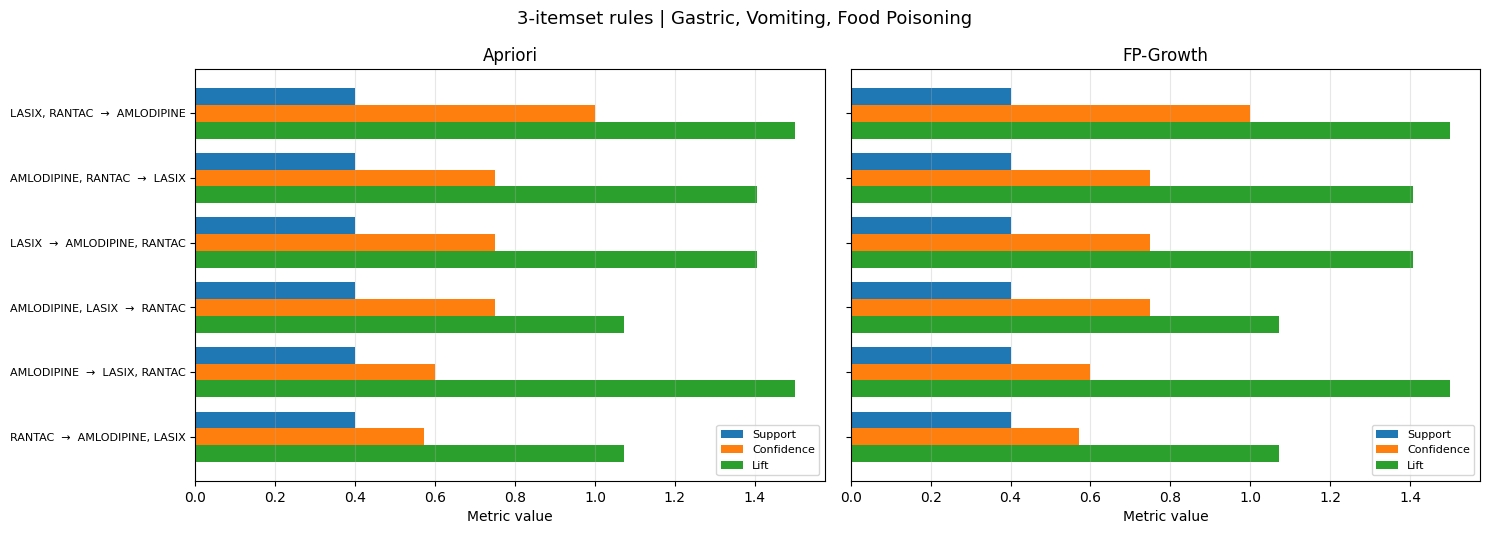

In [8]:
def plot_rules(symptom, n_items, title=None):
    """Grouped bars of support / confidence / lift per rule, Apriori (left) vs FP-Growth (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.45 * 12)), sharey=True)
    for ax, algo, name in zip(axes, ("apriori", "fpgrowth"), ("Apriori", "FP-Growth")):
        r = RESULTS[symptom][algo]["rules"]
        r = r[r.n_items == n_items].head(12).iloc[::-1]
        if r.empty:
            ax.set_title(f"{name}: no rules"); continue
        labels = r.Antecedents + "  →  " + r.Consequents
        y = np.arange(len(r)); h = 0.26
        ax.barh(y + h, r.support,    h, label="Support")
        ax.barh(y,     r.confidence, h, label="Confidence")
        ax.barh(y - h, r.lift,       h, label="Lift")
        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(name); ax.set_xlabel("Metric value"); ax.grid(axis="x", alpha=.3)
        ax.legend(loc="lower right", fontsize=8)
    fig.suptitle(title or f"{n_items}-itemset rules | {symptom}", fontsize=13)
    plt.tight_layout(); plt.show()

for symptom in SYMPTOM_FILES:
    for n in (2, 3):
        if (symptom, n) in TABLES:
            plot_rules(symptom, n)

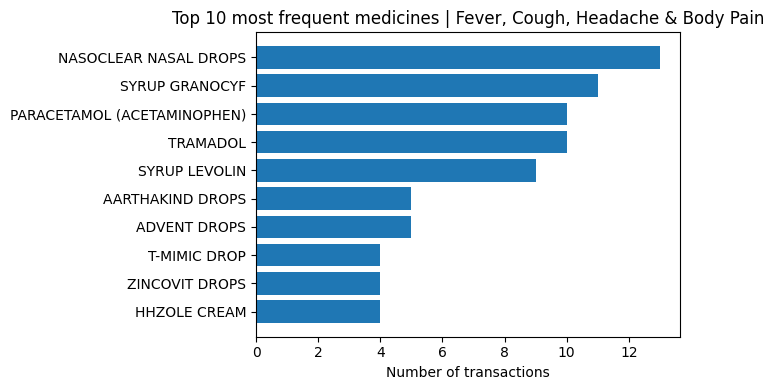

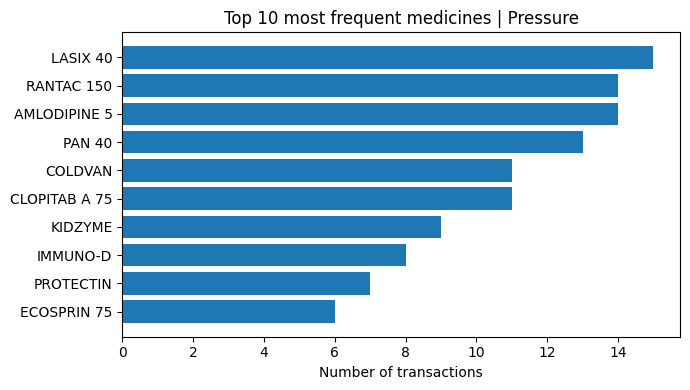

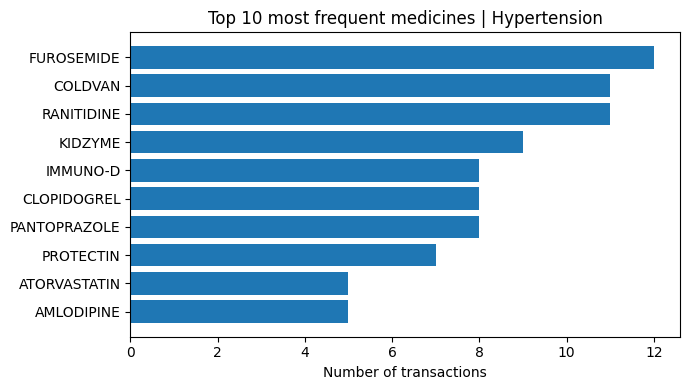

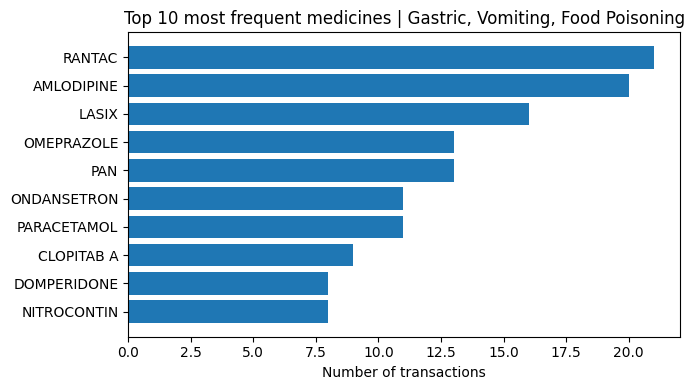

In [9]:
# Top single medicines per symptom group (item frequency)
for symptom, d in DATA.items():
    freq = d["onehot"].sum().sort_values(ascending=False).head(10)[::-1]
    plt.figure(figsize=(7, 4))
    plt.barh(freq.index, freq.values)
    plt.title(f"Top 10 most frequent medicines | {symptom}")
    plt.xlabel("Number of transactions"); plt.tight_layout(); plt.show()

In [10]:
if ALL_DATA_FILE:
    sector = pd.read_excel(ALL_DATA_FILE, sheet_name="Sheet3").dropna()
    chall  = pd.read_excel(ALL_DATA_FILE, sheet_name="Sheet4").dropna()

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].pie(sector.iloc[:, 1], labels=sector.iloc[:, 0], autopct="%1.0f%%", startangle=90, textprops={"fontsize": 8})
    axes[0].set_title("Fig. 1  Sector-wise inventory management usage")
    axes[1].pie(chall.iloc[:, 1], labels=chall.iloc[:, 0], autopct="%1.0f%%", startangle=90, textprops={"fontsize": 8})
    axes[1].set_title("Fig. 2  Challenges of inventory management")
    plt.tight_layout(); plt.show()

    freq = pd.read_excel(ALL_DATA_FILE, sheet_name="Sheet2").dropna().head(15)[::-1]
    plt.figure(figsize=(8, 5)); plt.barh(freq.iloc[:, 0], freq.iloc[:, 1])
    plt.title("Top 15 medicines by frequency (all prescriptions)"); plt.xlabel("Frequency")
    plt.tight_layout(); plt.show()
else:
    print("all_data workbook not uploaded; skipping Fig. 1 / Fig. 2.")

all_data workbook not uploaded; skipping Fig. 1 / Fig. 2.


In [11]:
def stock_priority(symptom, top_n=10):
    """Medicines ranked by how often they appear in the strongest rules (support x lift)."""
    r = RESULTS[symptom]["fpgrowth"]["rules"]
    r = r[r.n_items == 2]
    score = {}
    for _, row in r.iterrows():
        w = row.support * row.lift
        for med in (row.Antecedents, row.Consequents):
            score[med] = score.get(med, 0) + w
    s = pd.Series(score).sort_values(ascending=False).head(top_n)
    return s.rename("priority score").round(3).to_frame()

for symptom in SYMPTOM_FILES:
    print(f"\nMedicines to keep in stock | {symptom}")
    display(stock_priority(symptom))


Medicines to keep in stock | Fever, Cough, Headache & Body Pain


,priority score
PARACETAMOL (ACETAMINOPHEN),2.000
TRAMADOL,2.000
NASOCLEAR NASAL DROPS,1.692
SYRUP GRANOCYF,1.692



Medicines to keep in stock | Pressure


,priority score
LASIX 40,5.789
AMLODIPINE 5,5.457
RANTAC 150,5.281
PAN 40,5.277
CLOPITAB A 75,4.400
KIDZYME,3.414
COLDVAN,2.931
IMMUNO-D,1.140
ECOSPRIN 75,0.400
PROTECTIN,0.343



Medicines to keep in stock | Hypertension


,priority score
RANITIDINE,2.174
CLOPIDOGREL,1.636
COLDVAN,1.628
FUROSEMIDE,1.566
PANTOPRAZOLE,1.021



Medicines to keep in stock | Gastric, Vomiting, Food Poisoning


,priority score
AMLODIPINE,3.581
RANTAC,2.963
LASIX,2.457
OMEPRAZOLE,0.886
CLOPITAB A,0.450
PAN,0.312


In [12]:
OUT = "MBA_results.xlsx"
def short(s): return re.sub(r"[^A-Za-z0-9 ]", "", s)[:20].strip()

with pd.ExcelWriter(OUT, engine="openpyxl") as xl:
    COMPARISON.to_excel(xl, sheet_name="Comparison", index=False)
    for (symptom, n), t in TABLES.items():
        t.to_excel(xl, sheet_name=f"{short(symptom)} {n}-itemset"[:31], index=False)

print("Saved", OUT)
try:
    files.download(OUT)
except NameError:
    pass

Saved MBA_results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>